In [1]:
# ==============================================================
# LOCAL PROJECT SETUP (added during VS Code migration)
# Portable replacement for Google Colab / Google Drive mounting.
# All research code below this block is unchanged.
# ==============================================================
import sys as _sys
from pathlib import Path as _Path

def _locate_project_root():
    start = _Path.cwd().resolve()
    for candidate in [start] + list(start.parents):
        if (candidate / "src" / "ecg_qpain" / "paths.py").is_file():
            return candidate
    return start

PROJECT_ROOT = _locate_project_root()
_src = str(PROJECT_ROOT / "src")
if _src not in _sys.path:
    _sys.path.insert(0, _src)

from ecg_qpain.paths import (
    ROOT, BASE_DIR, PROJECT_DIR, DRIVE_DIR, MYDRIVE, MOUNT_POINT, mount_path,
    DATA_DIR, RAW_DIR, PROCESSED_DIR, MODELS_DIR, REPORTS_DIR,
    MITDB_DIR, NSTDB_DIR, MITDB_EXTRACTED, NSTDB_EXTRACTED,
    B2_DIR, B3_DIR, B4_DIR,
)
print("Local project root:", PROJECT_ROOT)
# ==============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from tqdm.notebook import tqdm

print("Libraries imported successfully!")

ModuleNotFoundError: No module named 'wfdb'

In [2]:
# (pip install moved to requirements.txt; run: pip install -r requirements.txt)

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from tqdm.notebook import tqdm

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import os

BASE_DIR = str(PROJECT_ROOT)

MITDB_DIR = os.path.join(
    BASE_DIR,
    "data/raw/mitdb/mit-bih-arrhythmia-database-1.0.0"
)

NSTDB_DIR = os.path.join(
    BASE_DIR,
    "data/raw/nstdb/mit-bih-noise-stress-test-database-1.0.0"
)

PROCESSED_DIR = os.path.join(BASE_DIR, "data/processed")
REPORT_DIR = os.path.join(BASE_DIR, "reports")

os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

FS = 360

print("Project paths configured!")
print("MITDB folder exists:", os.path.exists(MITDB_DIR))
print("NSTDB folder exists:", os.path.exists(NSTDB_DIR))
print("Processed folder exists:", os.path.exists(PROCESSED_DIR))
print("Report folder exists:", os.path.exists(REPORT_DIR))
print("Sampling Frequency:", FS)

Project paths configured!
MITDB folder exists: False
NSTDB folder exists: False
Processed folder exists: True
Report folder exists: True
Sampling Frequency: 360


In [5]:
noise_records = ["bw", "ma", "em"]

noise_info = []

for record_id in noise_records:

    record_path = os.path.join(NSTDB_DIR, record_id)

    signal, fields = wfdb.rdsamp(record_path)

    noise_info.append({
        "Record": record_id,
        "Shape": signal.shape,
        "Sampling_Frequency": fields["fs"],
        "Channels": ", ".join(fields["sig_name"]),
        "Units": ", ".join(fields["units"])
    })

noise_df = pd.DataFrame(noise_info)

display(noise_df)

noise_df.to_csv(
    os.path.join(REPORT_DIR, "noise_record_audit.csv"),
    index=False
)

print("Noise audit saved successfully!")

FileNotFoundError: [Errno 2] No such file or directory: '/content/gdrive/MyDrive/ECG_QPAIN_2027/data/raw/nstdb/mit-bih-noise-stress-test-database-1.0.0/bw.hea'

In [6]:
import os

print("NSTDB_DIR:")
print(NSTDB_DIR)

print("\nFolder exists:", os.path.exists(NSTDB_DIR))

if os.path.exists(NSTDB_DIR):
    print("\nFiles and folders inside NSTDB:")
    for item in sorted(os.listdir(NSTDB_DIR)):
        print(item)

NSTDB_DIR:
/content/gdrive/MyDrive/ECG_QPAIN_2027/data/raw/nstdb/mit-bih-noise-stress-test-database-1.0.0

Folder exists: False


In [8]:
import os

RAW_DIR = os.path.join(BASE_DIR, "data", "raw")

print("RAW_DIR exists:", os.path.exists(RAW_DIR))

if os.path.exists(RAW_DIR):

    print("\nFolders inside data/raw:")

    for root, dirs, files in os.walk(RAW_DIR):

        level = root.replace(RAW_DIR, "").count(os.sep)

        if level > 3:
            dirs[:] = []
            continue

        indent = "    " * level

        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:10]:
            print(f"{indent}    {file}")

RAW_DIR exists: False


In [9]:
import os

print("Checking Google Drive...")

print("Project root exists:",
      os.path.exists(str(PROJECT_ROOT)))

print("MyDrive-equivalent exists:",
      os.path.exists(str(PROJECT_ROOT)))

print("Project folder exists:",
      os.path.exists(str(PROJECT_ROOT)))

print("\nContent inside project root:")

print(os.listdir(str(PROJECT_ROOT)))

Checking Google Drive...
/content/gdrive exists: True
/content/gdrive/MyDrive exists: True
Project folder exists: True

Content inside /content:
['.config', 'gdrive', 'sample_data']


In [10]:
# (Colab Drive import removed - local execution)

# (Colab Drive mount removed - local execution)

ValueError: Mountpoint must not already contain files

In [11]:
import os

mount_path = str(PROJECT_ROOT)

print("Mountpoint exists:", os.path.exists(mount_path))

if os.path.exists(mount_path):
    print("\nMountpoint contents:")
    print(os.listdir(mount_path))

print("\nIs mountpoint a symlink:",
      os.path.islink(mount_path))

Mountpoint exists: True

Mountpoint contents:
['MyDrive']

Is mountpoint a symlink: False


In [12]:
import os

MYDRIVE = str(PROJECT_ROOT)

print("MyDrive exists:", os.path.exists(MYDRIVE))

print("\nMyDrive contents:")

if os.path.exists(MYDRIVE):
    for item in os.listdir(MYDRIVE)[:30]:
        print(item)

MyDrive exists: True

MyDrive contents:
ECG_QPAIN_2027


In [13]:
PROJECT_DIR = str(PROJECT_ROOT)

print("Project folder contents:\n")

for item in sorted(os.listdir(PROJECT_DIR)):
    item_path = os.path.join(PROJECT_DIR, item)

    if os.path.isdir(item_path):
        print(f"📁 {item}/")
        for sub_item in sorted(os.listdir(item_path)):
            print(f"    ├── {sub_item}")
    else:
        print(f"📄 {item}")

Project folder contents:

📁 data/
    ├── processed
📁 reports/


In [15]:
import os

print("Google Drive mounted:",
      os.path.ismount(str(PROJECT_ROOT)))

print("\nProcessed folder contents:")

processed_path = os.path.join(PROJECT_DIR, "data", "processed")

for item in sorted(os.listdir(processed_path)):
    print(item)

print("\nReports folder contents:")

for item in sorted(os.listdir(REPORT_DIR)):
    print(item)

Google Drive mounted: False

Processed folder contents:

Reports folder contents:


In [16]:
# (Colab Drive import removed - local execution)

# (Colab Drive mount removed - local execution)

Mounted at /content/gdrive_mount


In [17]:
import os

MYDRIVE = str(PROJECT_ROOT)

print("Google Drive mounted:",
      os.path.ismount(str(PROJECT_ROOT)))

print("\nMyDrive folders:")

print(os.listdir(MYDRIVE))

PROJECT_DIR = os.path.join(
    MYDRIVE,
    "ECG_QPAIN_2027"
)

print("\nECG Project exists:",
      os.path.exists(PROJECT_DIR))

if os.path.exists(PROJECT_DIR):
    print("\nProject contents:")
    print(os.listdir(PROJECT_DIR))

Google Drive mounted: True

MyDrive folders:
['Food quality around our campus.gform', 'Food quality around our campus (Responses).gsheet', 'Copy of Food quality around our campus.gform', 'ECG_QPAIN_2027']

ECG Project exists: True

Project contents:
['00_Colab_Setup_and_Data_Smoke_Test.ipynb', 'data', 'reports', '01_PhysioNet_Download_and_Data_Audit.ipynb', '02_Patient_Grouping_AAMI_Classification.ipynb', '03_ECG_Preprocessing_Beat_Extraction.ipynb', '04_ECG_Noise_Generation_and_SNR.ipynb']


In [18]:
import os

BASE_DIR = str(PROJECT_ROOT)

MITDB_DIR = os.path.join(
    BASE_DIR,
    "data/raw/mitdb/mit-bih-arrhythmia-database-1.0.0"
)

NSTDB_DIR = os.path.join(
    BASE_DIR,
    "data/raw/nstdb/mit-bih-noise-stress-test-database-1.0.0"
)

PROCESSED_DIR = os.path.join(
    BASE_DIR,
    "data/processed"
)

REPORT_DIR = os.path.join(
    BASE_DIR,
    "reports"
)

FS = 360

print("Project paths updated successfully!")

print("MITDB exists:", os.path.exists(MITDB_DIR))
print("NSTDB exists:", os.path.exists(NSTDB_DIR))
print("Processed exists:", os.path.exists(PROCESSED_DIR))
print("Reports exists:", os.path.exists(REPORT_DIR))

Project paths updated successfully!
MITDB exists: True
NSTDB exists: True
Processed exists: True
Reports exists: True


In [19]:
print("PROCESSED DATA FILES:\n")

for root, dirs, files in os.walk(PROCESSED_DIR):
    for file in sorted(files):
        print(os.path.join(root, file))

print("\nREPORT FILES:\n")

for root, dirs, files in os.walk(REPORT_DIR):
    for file in sorted(files):
        print(os.path.join(root, file))

PROCESSED DATA FILES:

/content/gdrive_mount/MyDrive/ECG_QPAIN_2027/data/processed/test_beats.npz
/content/gdrive_mount/MyDrive/ECG_QPAIN_2027/data/processed/test_metadata.csv
/content/gdrive_mount/MyDrive/ECG_QPAIN_2027/data/processed/train_beats.npz
/content/gdrive_mount/MyDrive/ECG_QPAIN_2027/data/processed/train_metadata.csv
/content/gdrive_mount/MyDrive/ECG_QPAIN_2027/data/processed/validation_beats.npz
/content/gdrive_mount/MyDrive/ECG_QPAIN_2027/data/processed/validation_metadata.csv

REPORT FILES:

/content/gdrive_mount/MyDrive/ECG_QPAIN_2027/reports/aami_class_summary.csv
/content/gdrive_mount/MyDrive/ECG_QPAIN_2027/reports/aami_record_counts.csv
/content/gdrive_mount/MyDrive/ECG_QPAIN_2027/reports/dataset_quality_report.csv
/content/gdrive_mount/MyDrive/ECG_QPAIN_2027/reports/ecg_channel_audit.csv
/content/gdrive_mount/MyDrive/ECG_QPAIN_2027/reports/mitdb_audit.csv
/content/gdrive_mount/MyDrive/ECG_QPAIN_2027/reports/nstdb_audit.csv
/content/gdrive_mount/MyDrive/ECG_QPAIN_202

In [20]:
import os
import wfdb
import pandas as pd
import numpy as np

noise_records = ["bw", "ma", "em"]

print("NSTDB Folder:", NSTDB_DIR)

print("\nAvailable NSTDB files:")

for file in sorted(os.listdir(NSTDB_DIR)):
    print(file)

NSTDB Folder: /content/gdrive_mount/MyDrive/ECG_QPAIN_2027/data/raw/nstdb/mit-bih-noise-stress-test-database-1.0.0

Available NSTDB files:
118e00.atr
118e00.dat
118e00.hea
118e00.xws
118e06.atr
118e06.dat
118e06.hea
118e06.xws
118e12.atr
118e12.dat
118e12.hea
118e12.xws
118e18.atr
118e18.dat
118e18.hea
118e18.xws
118e24.atr
118e24.dat
118e24.hea
118e24.xws
118e_6.atr
118e_6.dat
118e_6.hea
118e_6.xws
119e00.atr
119e00.dat
119e00.hea
119e00.xws
119e06.atr
119e06.dat
119e06.hea
119e06.xws
119e12.atr
119e12.dat
119e12.hea
119e12.xws
119e18.atr
119e18.dat
119e18.hea
119e18.xws
119e24.atr
119e24.dat
119e24.hea
119e24.xws
119e_6.atr
119e_6.dat
119e_6.hea
119e_6.xws
ANNOTATORS
RECORDS
SHA256SUMS.txt
bw.dat
bw.hea
bw.hea-
bw.xws
em.dat
em.hea
em.hea-
em.xws
ma.dat
ma.hea
ma.hea-
ma.xws
nstdb.doc
nstdb.txt
nstdbgen
nstdbgen-
old


In [21]:
noise_info = []

for record_id in noise_records:

    record_path = os.path.join(NSTDB_DIR, record_id)

    signal, fields = wfdb.rdsamp(record_path)

    noise_info.append({
        "Record": record_id.upper(),
        "Shape": signal.shape,
        "Sampling_Frequency": fields["fs"],
        "Channels": ", ".join(fields["sig_name"]),
        "Units": ", ".join(fields["units"]),
        "Duration_Seconds": len(signal) / fields["fs"],
        "NaN_Count": np.isnan(signal).sum(),
        "Inf_Count": np.isinf(signal).sum()
    })

noise_df = pd.DataFrame(noise_info)

display(noise_df)

audit_path = os.path.join(
    REPORT_DIR,
    "noise_record_audit.csv"
)

noise_df.to_csv(audit_path, index=False)

print("\nNoise audit saved successfully!")
print("Saved at:", audit_path)

,Record,Shape,Sampling_Frequency,Channels,Units,Duration_Seconds,NaN_Count,Inf_Count
0,BW,"(650000, 2)",360,"noise1, noise2","mV, mV",1805.555556,0,0
1,MA,"(650000, 2)",360,"noise1, noise2","mV, mV",1805.555556,0,0
2,EM,"(650000, 2)",360,"noise1, noise2","mV, mV",1805.555556,0,0



Noise audit saved successfully!
Saved at: /content/gdrive_mount/MyDrive/ECG_QPAIN_2027/reports/noise_record_audit.csv


In [22]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

noise_records = ["bw", "ma", "em"]

noise_signals = {}
noise_fields = {}

for record_id in noise_records:

    record_path = os.path.join(NSTDB_DIR, record_id)

    signal, fields = wfdb.rdsamp(record_path)

    noise_signals[record_id] = signal
    noise_fields[record_id] = fields

    print(
        f"{record_id.upper()} loaded | "
        f"Shape: {signal.shape} | "
        f"Sampling Rate: {fields['fs']} Hz"
    )

BW loaded | Shape: (650000, 2) | Sampling Rate: 360 Hz
MA loaded | Shape: (650000, 2) | Sampling Rate: 360 Hz
EM loaded | Shape: (650000, 2) | Sampling Rate: 360 Hz


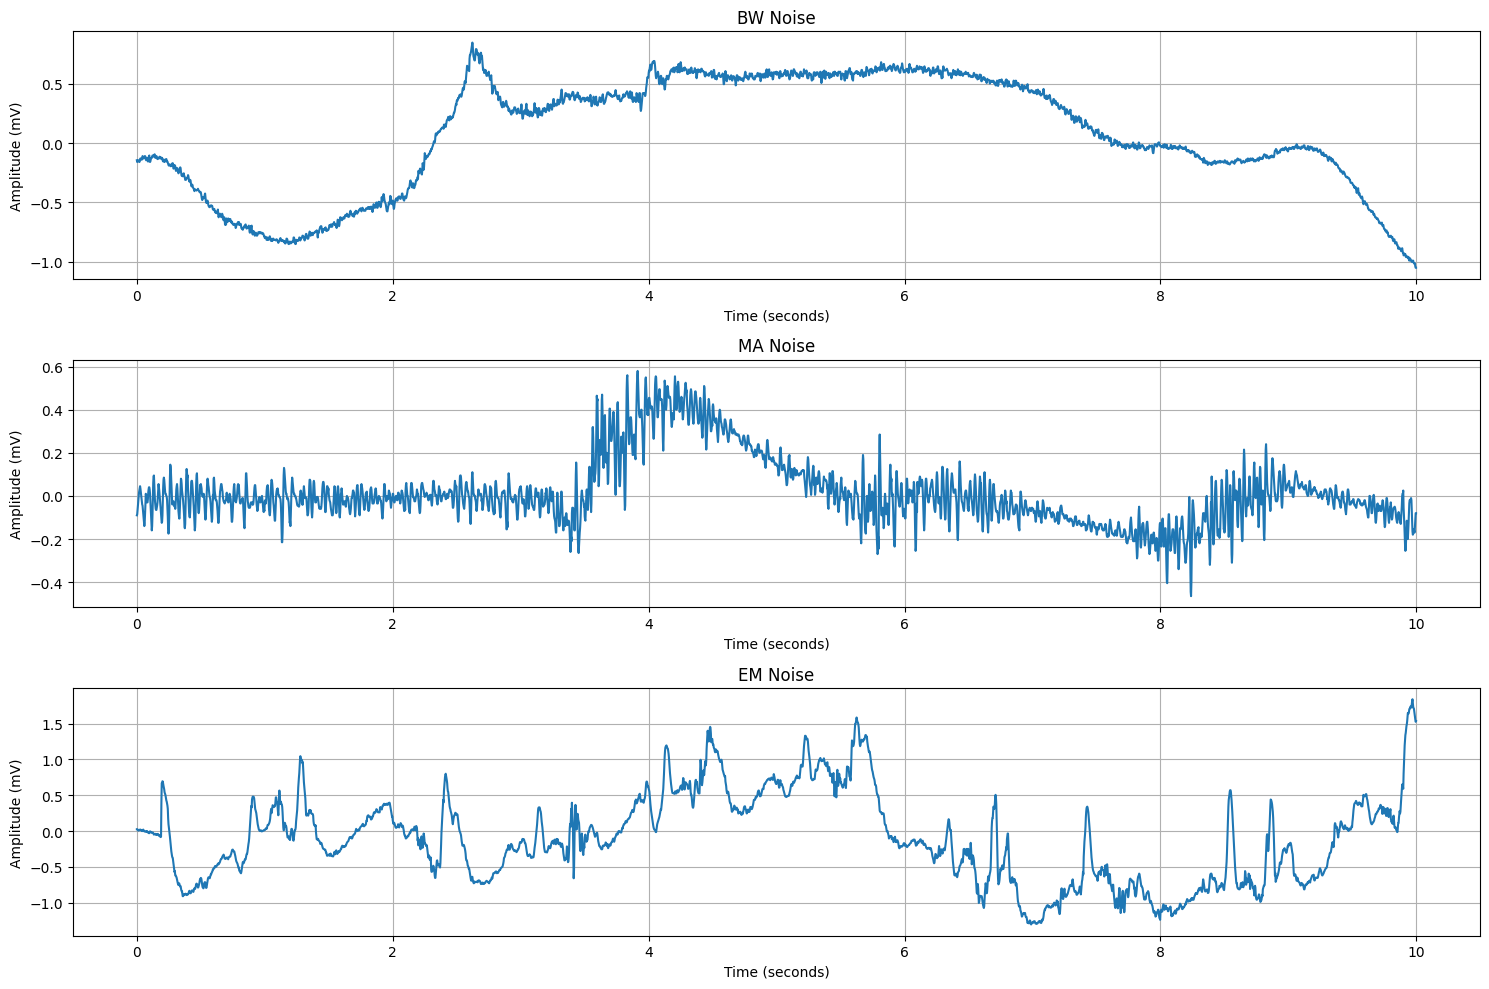

In [23]:
FS = 360

duration_samples = 3600
time = np.arange(duration_samples) / FS

plt.figure(figsize=(15, 10))

for i, record_id in enumerate(noise_records):

    signal = noise_signals[record_id][:duration_samples, 0]

    plt.subplot(3, 1, i + 1)

    plt.plot(time, signal)

    plt.title(f"{record_id.upper()} Noise")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude (mV)")
    plt.grid(True)

plt.tight_layout()
plt.show()

In [24]:
noise_statistics = []

for record_id in noise_records:

    signal = noise_signals[record_id][:, 0]

    noise_statistics.append({
        "Noise": record_id.upper(),
        "Mean": np.mean(signal),
        "Standard_Deviation": np.std(signal),
        "Minimum": np.min(signal),
        "Maximum": np.max(signal),
        "RMS": np.sqrt(np.mean(signal ** 2))
    })

noise_stats_df = pd.DataFrame(noise_statistics)

display(noise_stats_df)

noise_stats_df.to_csv(
    os.path.join(REPORT_DIR, "noise_statistics.csv"),
    index=False
)

print("Noise statistics saved successfully!")

,Noise,Mean,Standard_Deviation,Minimum,Maximum,RMS
0,BW,-0.001540,0.465894,-2.000,4.850,0.465897
1,MA,-0.002442,0.192669,-1.415,1.445,0.192684
2,EM,-0.002566,0.730151,-1.775,3.780,0.730156


Noise statistics saved successfully!


In [25]:
def generate_powerline_noise(
    length,
    fs=360,
    frequency=50,
    amplitude=1.0,
    phase=None
):

    if phase is None:
        phase = np.random.uniform(0, 2 * np.pi)

    t = np.arange(length) / fs

    noise = amplitude * np.sin(
        2 * np.pi * frequency * t + phase
    )

    return noise


test_50hz = generate_powerline_noise(
    length=3600,
    fs=FS,
    frequency=50
)

test_60hz = generate_powerline_noise(
    length=3600,
    fs=FS,
    frequency=60
)

print("50 Hz noise shape:", test_50hz.shape)
print("60 Hz noise shape:", test_60hz.shape)

50 Hz noise shape: (3600,)
60 Hz noise shape: (3600,)


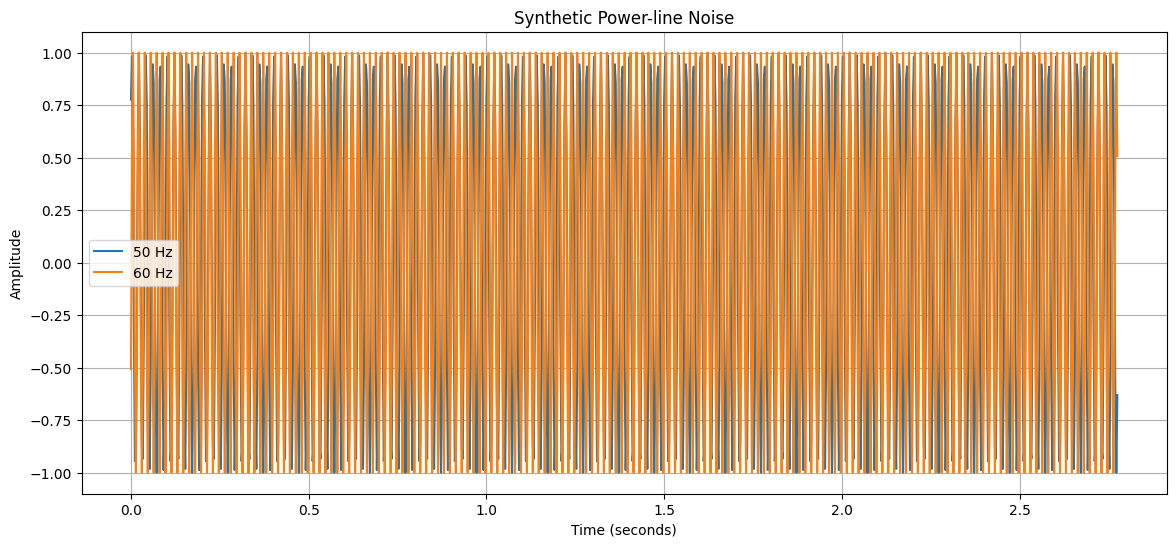

In [26]:
time = np.arange(1000) / FS

plt.figure(figsize=(14, 6))

plt.plot(time, test_50hz[:1000], label="50 Hz")
plt.plot(time, test_60hz[:1000], label="60 Hz")

plt.title("Synthetic Power-line Noise")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)

plt.show()

In [27]:
NOISE_SPLIT_RANGES = {}

TOTAL_NOISE_SAMPLES = 650000

train_end = int(TOTAL_NOISE_SAMPLES * 0.60)
val_end = int(TOTAL_NOISE_SAMPLES * 0.80)

NOISE_SPLIT_RANGES = {
    "train": (0, train_end),
    "validation": (train_end, val_end),
    "test": (val_end, TOTAL_NOISE_SAMPLES)
}

for split, (start, end) in NOISE_SPLIT_RANGES.items():

    print(
        f"{split.upper()}: "
        f"Start={start}, End={end}, "
        f"Samples={end-start}"
    )

TRAIN: Start=0, End=390000, Samples=390000
VALIDATION: Start=390000, End=520000, Samples=130000
TEST: Start=520000, End=650000, Samples=130000


In [28]:
train_range = NOISE_SPLIT_RANGES["train"]
val_range = NOISE_SPLIT_RANGES["validation"]
test_range = NOISE_SPLIT_RANGES["test"]

assert train_range[1] <= val_range[0]
assert val_range[1] <= test_range[0]

assert train_range[1] == val_range[0]
assert val_range[1] == test_range[0]

print("Train/Validation/Test noise regions are non-overlapping!")

Train/Validation/Test noise regions are non-overlapping!


In [29]:
BEAT_LENGTH = 288

def extract_noise_segment(
    noise_type,
    split,
    length=BEAT_LENGTH,
    channel=0,
    seed=None
):

    if noise_type not in noise_signals:
        raise ValueError("Unknown noise type")

    if split not in NOISE_SPLIT_RANGES:
        raise ValueError("Unknown split")

    signal = noise_signals[noise_type][:, channel]

    start_region, end_region = NOISE_SPLIT_RANGES[split]

    if end_region - start_region < length:
        raise ValueError("Noise region is too short")

    rng = np.random.default_rng(seed)

    start = rng.integers(
        start_region,
        end_region - length + 1
    )

    segment = signal[start:start + length]

    return segment, start

In [30]:
for split in ["train", "validation", "test"]:

    segment, start = extract_noise_segment(
        noise_type="bw",
        split=split,
        seed=42
    )

    print(
        f"{split.upper()} | "
        f"Segment Shape: {segment.shape} | "
        f"Start Index: {start}"
    )

TRAIN | Segment Shape: (288,) | Start Index: 34782
VALIDATION | Segment Shape: (288,) | Start Index: 401577
TEST | Segment Shape: (288,) | Start Index: 531577


In [32]:
def add_noise_at_snr(clean_signal, noise_segment, snr_db):

    clean_signal = np.asarray(
        clean_signal,
        dtype=np.float64
    )

    noise_segment = np.asarray(
        noise_segment,
        dtype=np.float64
    )

    if len(clean_signal) != len(noise_segment):
        raise ValueError("Signal and noise lengths must match")

    signal_power = np.mean(clean_signal ** 2)

    noise_power = np.mean(noise_segment ** 2)

    if signal_power <= 0 or noise_power <= 0:
        raise ValueError("Signal and noise power must be positive")

    target_noise_power = (
        signal_power / (10 ** (snr_db / 10))
    )

    scale = np.sqrt(
        target_noise_power / noise_power
    )

    scaled_noise = noise_segment * scale

    noisy_signal = clean_signal + scaled_noise

    return noisy_signal, scaled_noise

In [33]:
train_data = np.load(
    os.path.join(PROCESSED_DIR, "train_beats.npz")
)

print("Available keys:", train_data.files)

Available keys: ['X', 'y']


In [34]:
X_train = train_data["X"]

sample_ecg = X_train[0].astype(np.float64)

print("ECG Shape:", sample_ecg.shape)
print("Minimum:", sample_ecg.min())
print("Maximum:", sample_ecg.max())

ECG Shape: (288,)
Minimum: -0.1545787900686264
Maximum: 1.1559150218963623


In [35]:
bw_segment, bw_start = extract_noise_segment(
    noise_type="bw",
    split="train",
    seed=100
)

noisy_ecg, scaled_noise = add_noise_at_snr(
    sample_ecg,
    bw_segment,
    snr_db=12
)

print("Clean ECG:", sample_ecg.shape)
print("Noise:", scaled_noise.shape)
print("Noisy ECG:", noisy_ecg.shape)

Clean ECG: (288,)
Noise: (288,)
Noisy ECG: (288,)


In [36]:
actual_snr = 10 * np.log10(
    np.mean(sample_ecg ** 2) /
    np.mean(scaled_noise ** 2)
)

print("Target SNR: 12 dB")
print("Actual SNR:", round(actual_snr, 4), "dB")

Target SNR: 12 dB
Actual SNR: 12.0 dB


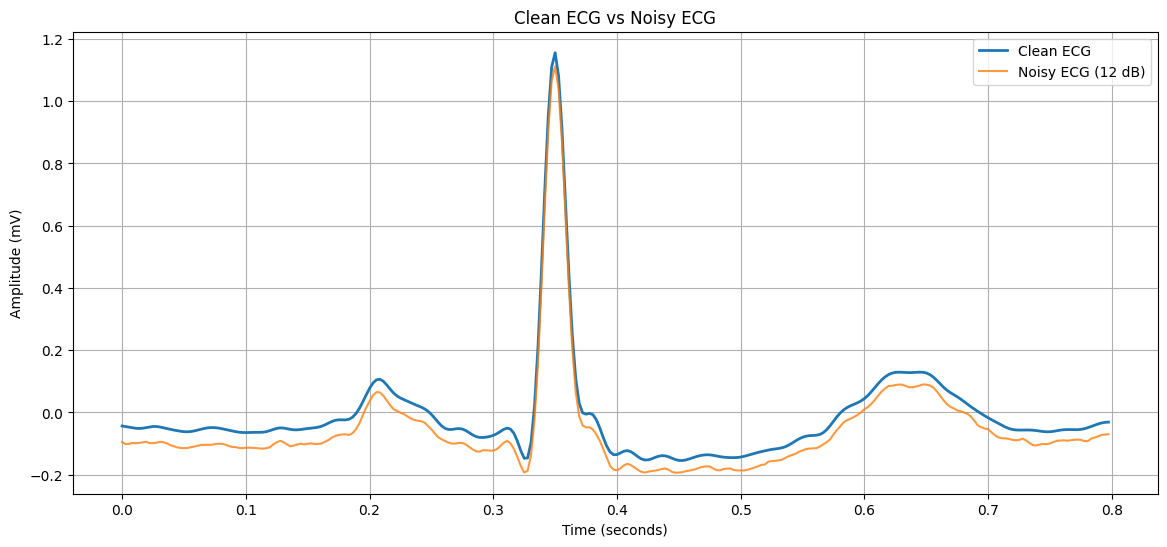

In [37]:
time = np.arange(BEAT_LENGTH) / FS

plt.figure(figsize=(14, 6))

plt.plot(
    time,
    sample_ecg,
    label="Clean ECG",
    linewidth=2
)

plt.plot(
    time,
    noisy_ecg,
    label="Noisy ECG (12 dB)",
    alpha=0.8
)

plt.title("Clean ECG vs Noisy ECG")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.grid(True)

plt.show()

In [38]:
TRAIN_SNRS = [24, 18, 12, 6]

VALIDATION_SNRS = [18, 12, 6]

TEST_SEEN_SNRS = [24, 18, 12, 6, 0]

TEST_UNSEEN_SNRS = [18, 12, 6, 0]

TEST_MIXED_SNRS = [12, 6, 0]

print("Research SNR configuration loaded!")

Research SNR configuration loaded!


In [39]:
def add_powerline_noise(
    clean_signal,
    frequency,
    snr_db,
    fs=360,
    seed=None
):

    rng = np.random.default_rng(seed)

    phase = rng.uniform(0, 2 * np.pi)

    powerline = generate_powerline_noise(
        length=len(clean_signal),
        fs=fs,
        frequency=frequency,
        amplitude=1.0,
        phase=phase
    )

    noisy_signal, scaled_noise = add_noise_at_snr(
        clean_signal,
        powerline,
        snr_db
    )

    return noisy_signal, scaled_noise

In [40]:
powerline_50, noise_50 = add_powerline_noise(
    sample_ecg,
    frequency=50,
    snr_db=12,
    seed=42
)

powerline_60, noise_60 = add_powerline_noise(
    sample_ecg,
    frequency=60,
    snr_db=12,
    seed=42
)

print("50 Hz noisy ECG:", powerline_50.shape)
print("60 Hz noisy ECG:", powerline_60.shape)

50 Hz noisy ECG: (288,)
60 Hz noisy ECG: (288,)


In [41]:
noise_config = {
    "sampling_frequency": FS,
    "beat_length": BEAT_LENGTH,
    "train_snrs": TRAIN_SNRS,
    "validation_snrs": VALIDATION_SNRS,
    "test_seen_snrs": TEST_SEEN_SNRS,
    "test_unseen_snrs": TEST_UNSEEN_SNRS,
    "test_mixed_snrs": TEST_MIXED_SNRS,
    "noise_types": ["BW", "MA", "EM"],
    "powerline_frequencies": [50, 60],
    "noise_channel": 0,
    "split_ranges": NOISE_SPLIT_RANGES
}

import json

config_path = os.path.join(
    REPORT_DIR,
    "noise_generation_config.json"
)

with open(config_path, "w") as f:
    json.dump(noise_config, f, indent=4)

print("Noise configuration saved!")
print(config_path)

Noise configuration saved!
/content/gdrive_mount/MyDrive/ECG_QPAIN_2027/reports/noise_generation_config.json


In [42]:
import os
import json
import numpy as np

# 1. Check configuration file
assert os.path.exists(config_path), "Config file missing!"

with open(config_path, "r") as f:
    saved_config = json.load(f)

# 2. Check processed datasets
required_files = [
    "train_beats.npz",
    "validation_beats.npz",
    "test_beats.npz"
]

for filename in required_files:
    path = os.path.join(PROCESSED_DIR, filename)
    assert os.path.exists(path), f"Missing: {filename}"

# 3. Check noise split boundaries
train_range = NOISE_SPLIT_RANGES["train"]
val_range = NOISE_SPLIT_RANGES["validation"]
test_range = NOISE_SPLIT_RANGES["test"]

assert train_range[1] <= val_range[0]
assert val_range[1] <= test_range[0]

# 4. Check SNR function
test_ecg = X_train[0]
test_noise, _ = extract_noise_segment(
    "bw", "train", length=288, seed=2027
)

test_noisy, scaled_noise = add_noise_at_snr(
    test_ecg, test_noise, 12
)

actual_snr = 10 * np.log10(
    np.mean(test_ecg ** 2) /
    np.mean(scaled_noise ** 2)
)

assert abs(actual_snr - 12) < 0.01

print("Configuration file: OK")
print("Processed datasets: OK")
print("Noise split boundaries: OK")
print("SNR verification:", round(actual_snr, 2), "dB")
print("NOTEBOOK 04 VALIDATION PASSED!")

Configuration file: OK
Processed datasets: OK
Noise split boundaries: OK
SNR verification: 12.0 dB
NOTEBOOK 04 VALIDATION PASSED!
